<a href="https://colab.research.google.com/github/Abhishek-M-G/Abhi-repository/blob/main/sms_data_poisoning_experiments.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q pandas numpy scikit-learn matplotlib seaborn

In [ ]:
import pandas as pd
import zipfile
import requests
from io import BytesIO

url = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"

response = requests.get(url, timeout=60)
response.raise_for_status()

with zipfile.ZipFile(BytesIO(response.content)) as z:
    with z.open("SMSSpamCollection") as f:
        df = pd.read_csv(
            f,
            sep="\t",
            header=None,
            names=["label", "message"]
        )

print("Dataset loaded:", df.shape)
print(df.head())
print(df["label"].value_counts())

Dataset loaded: (5572, 2)
  label                                            message
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...
label
ham     4825
spam     747
Name: count, dtype: int64


In [ ]:
df = df.dropna()

df["label"] = df["label"].map({
    "ham": 0,
    "spam": 1
})

df["message"] = df["message"].str.lower()

print(df.head())
print(df["label"].value_counts())


   label                                            message
0      0  go until jurong point, crazy.. available only ...
1      0                      ok lar... joking wif u oni...
2      1  free entry in 2 a wkly comp to win fa cup fina...
3      0  u dun say so early hor... u c already then say...
4      0  nah i don't think he goes to usf, he lives aro...
label
0    4825
1     747
Name: count, dtype: int64


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    df["message"],
    df["label"],
    test_size=0.2,
    random_state=42,
    stratify=df["label"]
)

print("Training:", len(X_train))
print("Testing:", len(X_test))

Training: 4457
Testing: 1115


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(
    max_features=5000,
    stop_words="english"
)

X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

print("Training features:", X_train_tfidf.shape)
print("Testing features:", X_test_tfidf.shape)

Training features: (4457, 5000)
Testing features: (1115, 5000)


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score

baseline_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced"
)

baseline_model.fit(X_train_tfidf, y_train)

predictions = baseline_model.predict(X_test_tfidf)

print("Clean Model Accuracy:",
      accuracy_score(y_test, predictions))

print(classification_report(
    y_test,
    predictions,
    target_names=["Ham", "Spam"]
))

Clean Model Accuracy: 0.9766816143497757
              precision    recall  f1-score   support

         Ham       0.99      0.99      0.99       966
        Spam       0.91      0.91      0.91       149

    accuracy                           0.98      1115
   macro avg       0.95      0.95      0.95      1115
weighted avg       0.98      0.98      0.98      1115



In [ ]:
import joblib

joblib.dump(baseline_model, "clean_baseline_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [ ]:
joblib.dump(tfidf_vectorizer, "tfidf_vectorizer.pkl")

print("Vectorizer saved successfully!")

NameError: name 'tfidf_vectorizer' is not defined

In [ ]:
%whos


Variable                Type                  Data/Info
-------------------------------------------------------
BytesIO                 type                  <class '_io.BytesIO'>
LogisticRegression      type                  <class 'sklearn.linear_mo<...>stic.LogisticRegression'>
TfidfVectorizer         type                  <class 'sklearn.feature_e<...>on.text.TfidfVectorizer'>
X_test                  Series                2825      no need to buy <...>ngth: 1115, dtype: object
X_test_tfidf            csr_matrix            <Compressed Sparse Row sp<...>4675)	0.47475459837252315
X_train                 Series                184                      <...>ngth: 4457, dtype: object
X_train_tfidf           csr_matrix            <Compressed Sparse Row sp<...>2284)	0.39693106423747165
accuracy_score          function              <function accuracy_score at 0x7a12b010fba0>
baseline_model          LogisticRegression    LogisticRegression(class_<...>balanced', max_iter=1000)
classification_r

In [ ]:
import joblib

# Save the fitted TF-IDF vectorizer
joblib.dump(vectorizer, "tfidf_vectorizer.pkl")

print("files saved successfully!")

files saved successfully!


In [ ]:
import os

print(os.getcwd())
print(os.path.exists("clean_baseline_model.pkl"))
print(os.path.exists("tfidf_vectorizer.pkl"))

/content
True
True


In [ ]:
import numpy as np

# Reproducibility
random_seed = 42
rng = np.random.default_rng(random_seed)

# Create a copy of the original training labels
y_train_poisoned_1 = y_train.copy()

# Calculate 1% of the total training dataset
poison_count = int(0.01 * len(y_train))

# Find positions of Ham samples (label = 0)
ham_positions = np.flatnonzero(y_train.to_numpy() == 0)

# Randomly select Ham samples for poisoning
poison_positions = rng.choice(
    ham_positions,
    size=poison_count,
    replace=False
)

# Flip selected labels from Ham (0) to Spam (1)
y_train_poisoned_1.iloc[poison_positions] = 1

print("Total training samples:", len(y_train))
print("Poisoned samples:", poison_count)
print("Actual poisoning rate:",
      poison_count / len(y_train) * 100, "%")

Total training samples: 4457
Poisoned samples: 44
Actual poisoning rate: 0.9872111285618129 %


In [ ]:
from sklearn.linear_model import LogisticRegression

poisoned_model_1 = LogisticRegression(
    max_iter=1000,
    class_weight="balanced"
)

poisoned_model_1.fit(
    X_train_tfidf,
    y_train_poisoned_1
)

print("1% Poisoned Model Trained Successfully!")

1% Poisoned Model Trained Successfully!


In [ ]:
from sklearn.metrics import accuracy_score, classification_report

poisoned_predictions_1 = poisoned_model_1.predict(X_test_tfidf)

print("1% Poisoned Model Accuracy:",
      accuracy_score(y_test, poisoned_predictions_1))

print(classification_report(
    y_test,
    poisoned_predictions_1,
    target_names=["Ham", "Spam"]
))

1% Poisoned Model Accuracy: 0.9721973094170404
              precision    recall  f1-score   support

         Ham       0.99      0.98      0.98       966
        Spam       0.88      0.91      0.90       149

    accuracy                           0.97      1115
   macro avg       0.93      0.95      0.94      1115
weighted avg       0.97      0.97      0.97      1115



In [ ]:
print("Clean Baseline Accuracy:",
      accuracy_score(y_test, baseline_model.predict(X_test_tfidf)))

print("1% Poisoned Accuracy:",
      accuracy_score(y_test, poisoned_predictions_1))

Clean Baseline Accuracy: 0.9766816143497757
1% Poisoned Accuracy: 0.9721973094170404


In [ ]:
# 5 % poinsoing starts

In [ ]:
# Create a fresh copy of original training labels
y_train_poisoned_5 = y_train.copy()

# Calculate 5% poisoning count
poison_count_5 = int(0.05 * len(y_train))

# Find Ham sample positions
ham_positions = np.flatnonzero(y_train.to_numpy() == 0)

# Use a reproducible random selection
rng_5 = np.random.default_rng(42)

poison_positions_5 = rng_5.choice(
    ham_positions,
    size=poison_count_5,
    replace=False
)

# Flip Ham labels to Spam
y_train_poisoned_5.iloc[poison_positions_5] = 1

print("Total training samples:", len(y_train))
print("Poisoned samples:", poison_count_5)
print("Actual poisoning rate:",
      poison_count_5 / len(y_train) * 100, "%")

Total training samples: 4457
Poisoned samples: 222
Actual poisoning rate: 4.98092887592551 %


In [ ]:
poisoned_model_5 = LogisticRegression(
    max_iter=1000,
    class_weight="balanced"
)

poisoned_model_5.fit(
    X_train_tfidf,
    y_train_poisoned_5
)

print("5% Poisoned Model Trained!")

5% Poisoned Model Trained!


In [ ]:
predictions_5 = poisoned_model_5.predict(X_test_tfidf)

print("5% Poisoned Accuracy:",
      accuracy_score(y_test, predictions_5))

print(classification_report(
    y_test,
    predictions_5,
    target_names=["Ham", "Spam"]
))

5% Poisoned Accuracy: 0.9408071748878923
              precision    recall  f1-score   support

         Ham       0.99      0.94      0.96       966
        Spam       0.71      0.94      0.81       149

    accuracy                           0.94      1115
   macro avg       0.85      0.94      0.89      1115
weighted avg       0.95      0.94      0.94      1115



In [ ]:
# 10 % poisoning injection


In [ ]:
# Fresh copy of original labels
y_train_poisoned_10 = y_train.copy()

# Calculate 10% poisoning count
poison_count_10 = int(0.10 * len(y_train))

# Select Ham positions
ham_positions = np.flatnonzero(y_train.to_numpy() == 0)

# Reproducible random selection
rng_10 = np.random.default_rng(42)

poison_positions_10 = rng_10.choice(
    ham_positions,
    size=poison_count_10,
    replace=False
)

# Flip labels
y_train_poisoned_10.iloc[poison_positions_10] = 1

print("Total training samples:", len(y_train))
print("Poisoned samples:", poison_count_10)
print("Actual poisoning rate:",
      poison_count_10 / len(y_train) * 100, "%")

Total training samples: 4457
Poisoned samples: 445
Actual poisoning rate: 9.984294368409245 %


In [ ]:
poisoned_model_10 = LogisticRegression(
    max_iter=1000,
    class_weight="balanced"
)

poisoned_model_10.fit(
    X_train_tfidf,
    y_train_poisoned_10
)

predictions_10 = poisoned_model_10.predict(X_test_tfidf)

print("10% Poisoned Accuracy:",
      accuracy_score(y_test, predictions_10))

print(classification_report(
    y_test,
    predictions_10,
    target_names=["Ham", "Spam"]
))

10% Poisoned Accuracy: 0.9255605381165919
              precision    recall  f1-score   support

         Ham       0.99      0.92      0.96       966
        Spam       0.65      0.95      0.77       149

    accuracy                           0.93      1115
   macro avg       0.82      0.94      0.86      1115
weighted avg       0.95      0.93      0.93      1115



In [ ]:
import joblib

joblib.dump(poisoned_model_1, "label_flip_1_percent.pkl")
joblib.dump(poisoned_model_5, "label_flip_5_percent.pkl")
joblib.dump(poisoned_model_10, "label_flip_10_percent.pkl")

print("All poisoned models saved successfully!")

All poisoned models saved successfully!


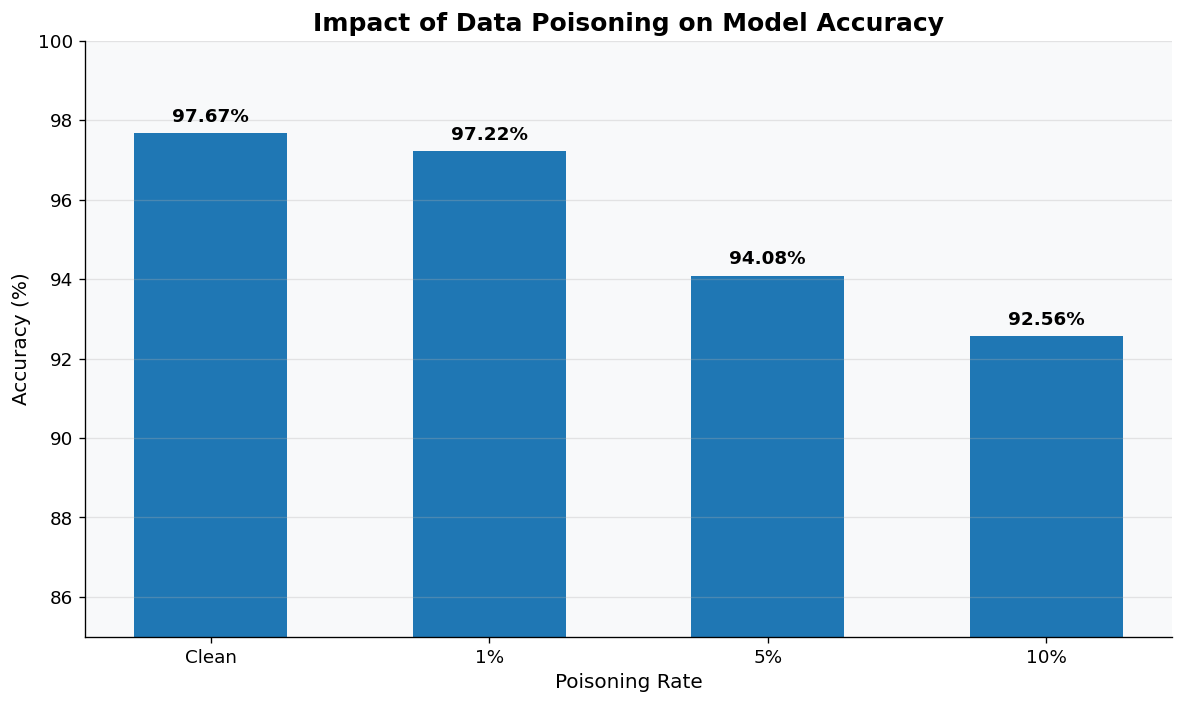

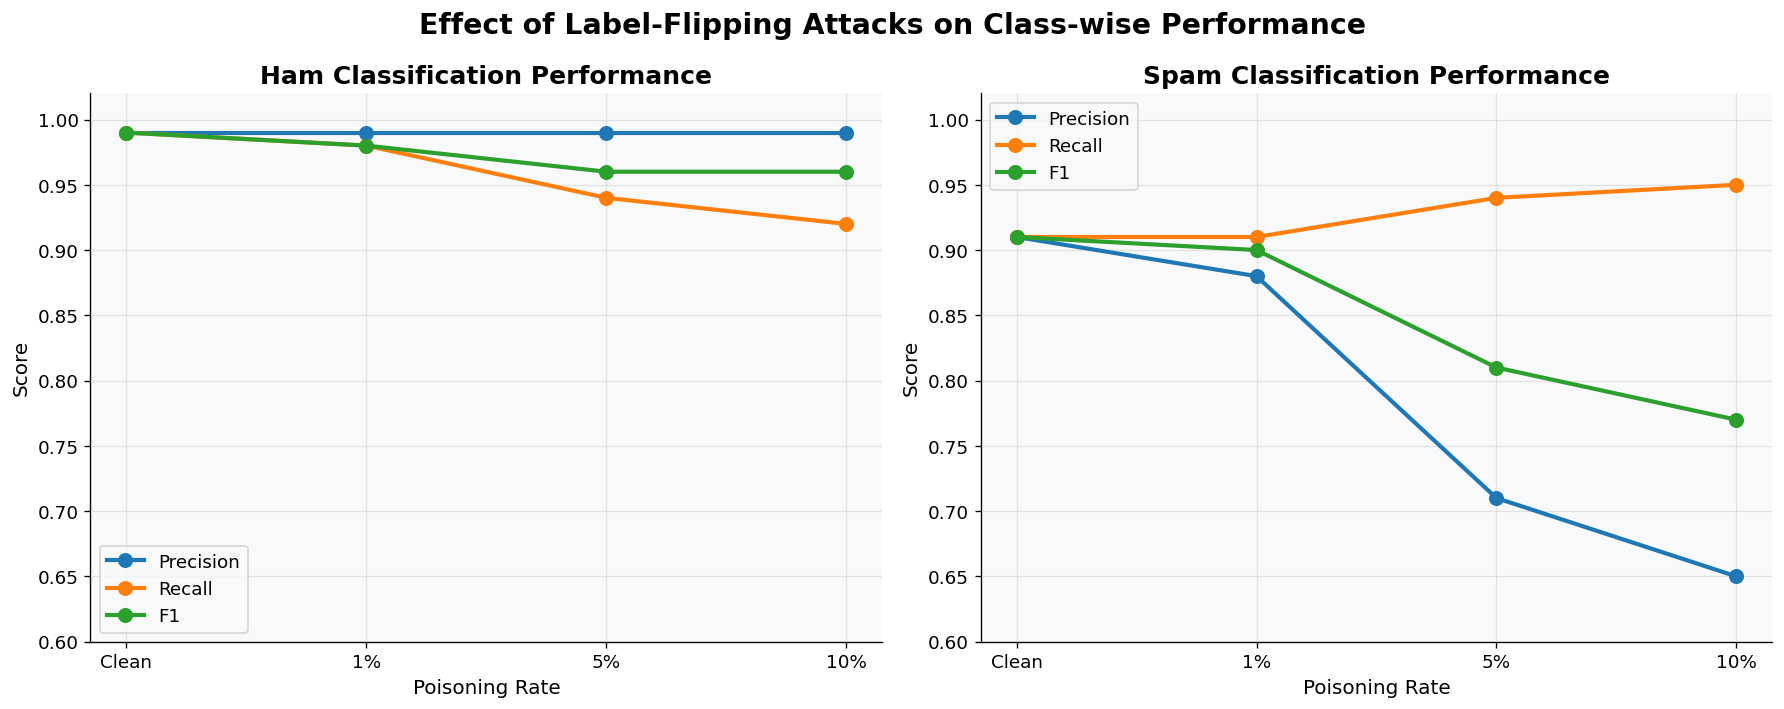

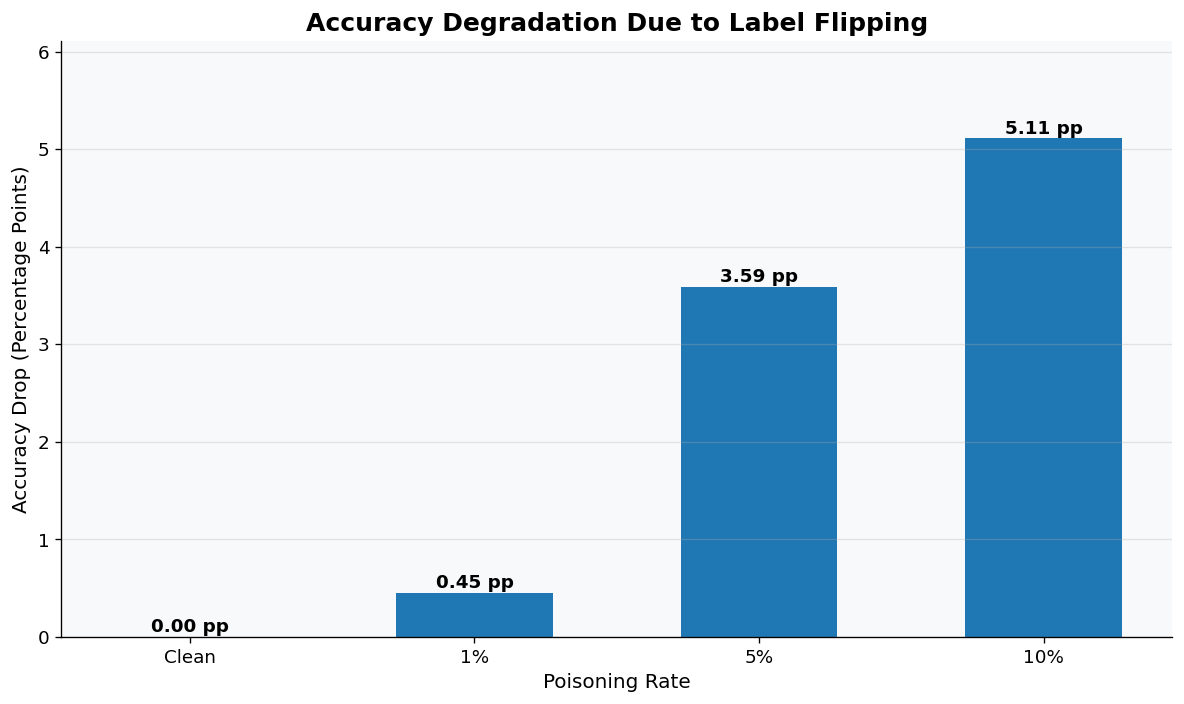

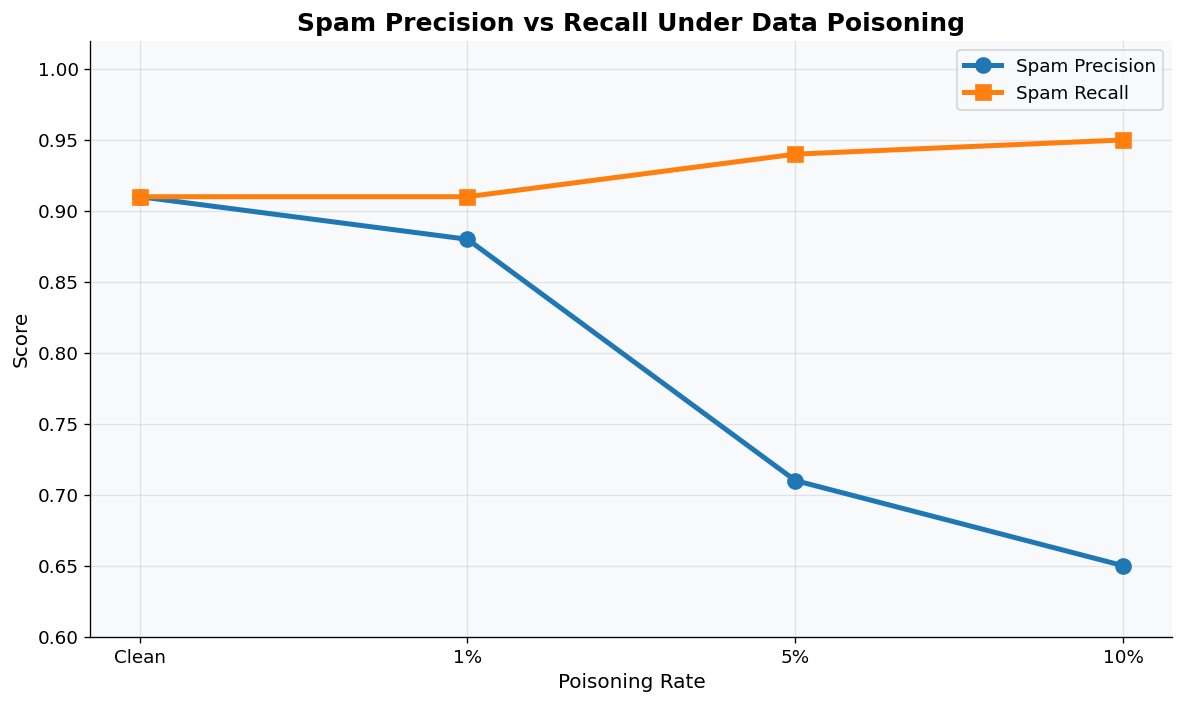

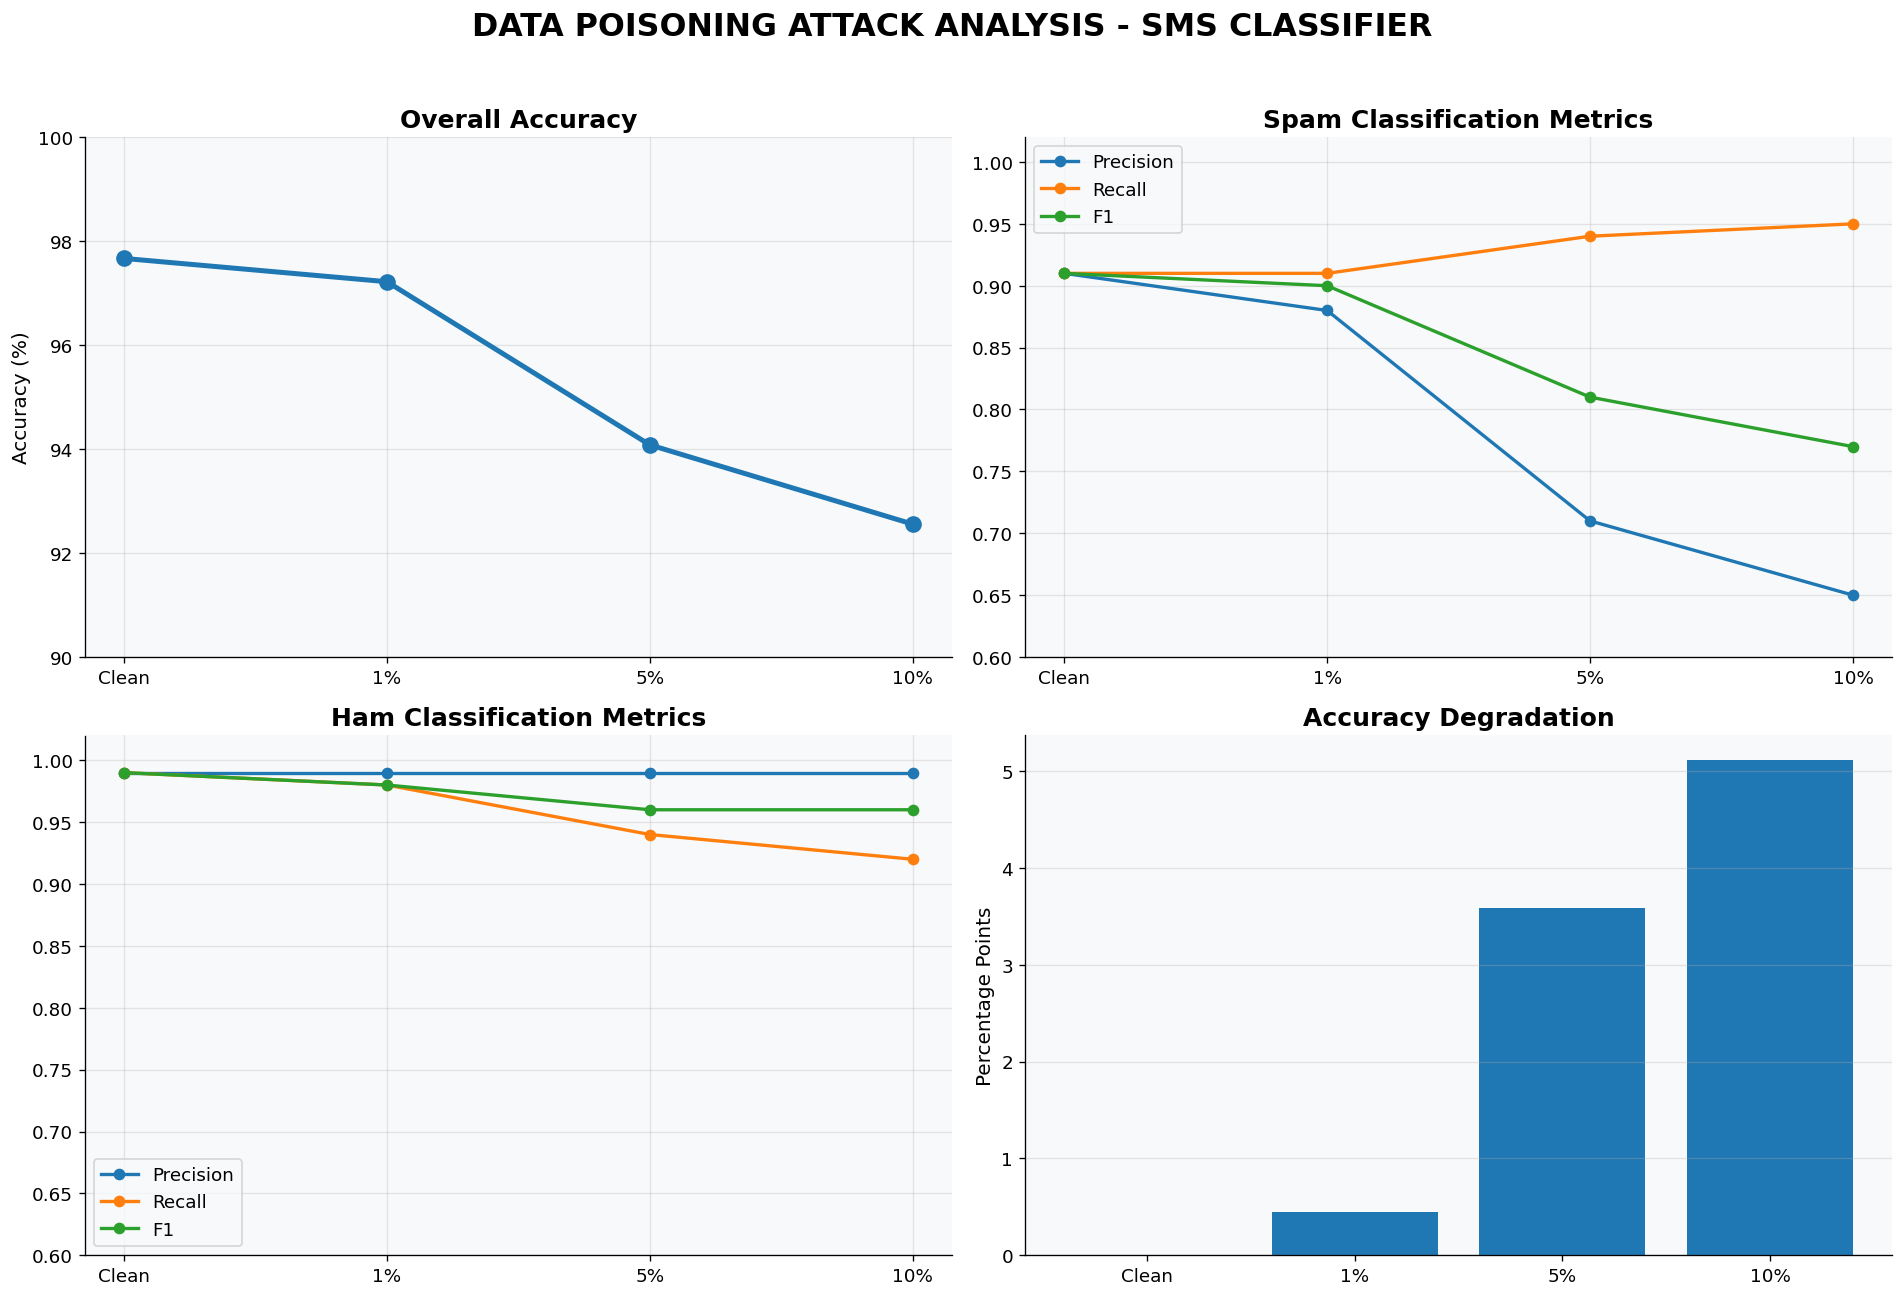

ALL VISUALIZATIONS GENERATED SUCCESSFULLY!
Saved inside: /content/poisoning_comparisons
['experimental_results.csv', '01_accuracy_comparison.png', '02_classwise_metrics.png', '03_accuracy_degradation.png', '02_classwise_metrics.pdf', '05_complete_dashboard.png', '03_accuracy_degradation.pdf', '05_complete_dashboard.pdf', '01_accuracy_comparison.pdf', '04_spam_precision_recall.pdf', '04_spam_precision_recall.png']


In [ ]:

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ==========================================
# 1. EXPERIMENTAL RESULTS
# ==========================================

results = pd.DataFrame({
    "Poisoning Rate": ["Clean", "1%", "5%", "10%"],
    "Accuracy": [97.668, 97.220, 94.081, 92.556],

    # Values taken from your classification reports
    "Ham Precision": [0.99, 0.99, 0.99, 0.99],
    "Ham Recall":    [0.99, 0.98, 0.94, 0.92],
    "Ham F1":        [0.99, 0.98, 0.96, 0.96],

    "Spam Precision": [0.91, 0.88, 0.71, 0.65],
    "Spam Recall":    [0.91, 0.91, 0.94, 0.95],
    "Spam F1":        [0.91, 0.90, 0.81, 0.77]
})

# Create output folder
output_dir = "poisoning_comparisons"
os.makedirs(output_dir, exist_ok=True)

# Professional graph settings
plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "font.size": 11,
    "axes.titlesize": 15,
    "axes.labelsize": 12,
    "axes.titleweight": "bold",
    "figure.facecolor": "white",
    "axes.facecolor": "#f8f9fa",
    "axes.spines.top": False,
    "axes.spines.right": False
})

x = np.arange(len(results))
labels = results["Poisoning Rate"]

# ==========================================
# 2. ACCURACY COMPARISON
# ==========================================

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.bar(
    labels,
    results["Accuracy"],
    width=0.55
)

ax.set_title("Impact of Data Poisoning on Model Accuracy")
ax.set_xlabel("Poisoning Rate")
ax.set_ylabel("Accuracy (%)")
ax.set_ylim(85, 100)
ax.grid(axis="y", alpha=0.3)

for bar, value in zip(bars, results["Accuracy"]):
    ax.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 0.3,
        f"{value:.2f}%",
        ha="center",
        fontweight="bold"
    )

plt.tight_layout()
plt.savefig(f"{output_dir}/01_accuracy_comparison.png",
            bbox_inches="tight")
plt.savefig(f"{output_dir}/01_accuracy_comparison.pdf",
            bbox_inches="tight")
plt.show()

# ==========================================
# 3. HAM VS SPAM METRICS
# ==========================================

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

metrics = ["Precision", "Recall", "F1"]

for ax, category in zip(axes, ["Ham", "Spam"]):

    for metric in metrics:
        column = f"{category} {metric}"
        ax.plot(
            labels,
            results[column],
            marker="o",
            linewidth=2.5,
            markersize=8,
            label=metric
        )

    ax.set_title(f"{category} Classification Performance")
    ax.set_xlabel("Poisoning Rate")
    ax.set_ylabel("Score")
    ax.set_ylim(0.60, 1.02)
    ax.grid(alpha=0.3)
    ax.legend()

plt.suptitle(
    "Effect of Label-Flipping Attacks on Class-wise Performance",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout()
plt.savefig(f"{output_dir}/02_classwise_metrics.png",
            bbox_inches="tight")
plt.savefig(f"{output_dir}/02_classwise_metrics.pdf",
            bbox_inches="tight")
plt.show()

# ==========================================
# 4. ACCURACY DEGRADATION
# ==========================================

baseline_accuracy = results.loc[0, "Accuracy"]

degradation = baseline_accuracy - results["Accuracy"]

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.bar(
    labels,
    degradation,
    width=0.55
)

ax.set_title("Accuracy Degradation Due to Label Flipping")
ax.set_xlabel("Poisoning Rate")
ax.set_ylabel("Accuracy Drop (Percentage Points)")
ax.grid(axis="y", alpha=0.3)

for bar, value in zip(bars, degradation):
    ax.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 0.05,
        f"{value:.2f} pp",
        ha="center",
        fontweight="bold"
    )

ax.set_ylim(0, max(degradation) + 1)

plt.tight_layout()
plt.savefig(f"{output_dir}/03_accuracy_degradation.png",
            bbox_inches="tight")
plt.savefig(f"{output_dir}/03_accuracy_degradation.pdf",
            bbox_inches="tight")
plt.show()

# ==========================================
# 5. SPAM PRECISION VS RECALL
# ==========================================

fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(
    labels,
    results["Spam Precision"],
    marker="o",
    linewidth=3,
    markersize=9,
    label="Spam Precision"
)

ax.plot(
    labels,
    results["Spam Recall"],
    marker="s",
    linewidth=3,
    markersize=9,
    label="Spam Recall"
)

ax.set_title("Spam Precision vs Recall Under Data Poisoning")
ax.set_xlabel("Poisoning Rate")
ax.set_ylabel("Score")
ax.set_ylim(0.60, 1.02)
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.savefig(f"{output_dir}/04_spam_precision_recall.png",
            bbox_inches="tight")
plt.savefig(f"{output_dir}/04_spam_precision_recall.pdf",
            bbox_inches="tight")
plt.show()

# ==========================================
# 6. COMBINED RESEARCH DASHBOARD
# ==========================================

fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# Accuracy
axes[0, 0].plot(
    labels, results["Accuracy"],
    marker="o", linewidth=3, markersize=9
)
axes[0, 0].set_title("Overall Accuracy")
axes[0, 0].set_ylabel("Accuracy (%)")
axes[0, 0].set_ylim(90, 100)
axes[0, 0].grid(alpha=0.3)

# Spam metrics
for metric in metrics:
    axes[0, 1].plot(
        labels,
        results[f"Spam {metric}"],
        marker="o",
        linewidth=2,
        label=metric
    )

axes[0, 1].set_title("Spam Classification Metrics")
axes[0, 1].set_ylim(0.60, 1.02)
axes[0, 1].legend()
axes[0, 1].grid(alpha=0.3)

# Ham metrics
for metric in metrics:
    axes[1, 0].plot(
        labels,
        results[f"Ham {metric}"],
        marker="o",
        linewidth=2,
        label=metric
    )

axes[1, 0].set_title("Ham Classification Metrics")
axes[1, 0].set_ylim(0.60, 1.02)
axes[1, 0].legend()
axes[1, 0].grid(alpha=0.3)

# Accuracy degradation
axes[1, 1].bar(labels, degradation)
axes[1, 1].set_title("Accuracy Degradation")
axes[1, 1].set_ylabel("Percentage Points")
axes[1, 1].grid(axis="y", alpha=0.3)

fig.suptitle(
    "DATA POISONING ATTACK ANALYSIS - SMS CLASSIFIER",
    fontsize=19,
    fontweight="bold"
)

plt.tight_layout(rect=[0, 0, 1, 0.96])

plt.savefig(f"{output_dir}/05_complete_dashboard.png",
            bbox_inches="tight")
plt.savefig(f"{output_dir}/05_complete_dashboard.pdf",
            bbox_inches="tight")
plt.show()

# ==========================================
# 7. EXPORT RESULTS AS CSV
# ==========================================

results.to_csv(
    f"{output_dir}/experimental_results.csv",
    index=False
)

print("ALL VISUALIZATIONS GENERATED SUCCESSFULLY!")
print("Saved inside:", os.path.abspath(output_dir))
print(os.listdir(output_dir))


In [ ]:
# start with the backdoor poisoning attack(BadNets style)

In [ ]:
# Backdoor attack configuration

SOURCE_LABEL = 0       # Ham
TARGET_LABEL = 1       # Spam
TRIGGER = "zxqvtoken"

# Check original training data
trigger_count = X_train.str.contains(
    TRIGGER,
    case=False,
    regex=False
).sum()

source_count = (y_train == SOURCE_LABEL).sum()
target_count = (y_train == TARGET_LABEL).sum()

print("Backdoor Attack Configuration")
print("--------------------------------")
print("Source class (Ham):", source_count)
print("Target class (Spam):", target_count)
print("Trigger:", TRIGGER)
print("Existing trigger occurrences:", trigger_count)

if trigger_count == 0:
    print("\nTrigger is suitable for the experiment!")
else:
    print("\nChoose a different trigger.")

NameError: name 'X_train' is not defined

In [ ]:
import numpy as np

# Preserve original training data
X_train_backdoor_1 = X_train.copy()
y_train_backdoor_1 = y_train.copy()

# Calculate poisoning count
poison_count = int(0.01 * len(X_train))

# Find Ham message positions
ham_positions = np.flatnonzero(
    y_train.to_numpy() == SOURCE_LABEL
)

# Select random Ham messages
rng = np.random.default_rng(42)

poison_positions = rng.choice(
    ham_positions,
    size=poison_count,
    replace=False
)

# Insert trigger into selected messages
X_train_backdoor_1.iloc[poison_positions] = (
    X_train_backdoor_1.iloc[poison_positions]
    + " "
    + TRIGGER
)

# Change selected labels to Spam
y_train_backdoor_1.iloc[poison_positions] = TARGET_LABEL

print("Backdoor dataset created!")
print("Total training messages:", len(X_train))
print("Poisoned messages:", poison_count)
print("Actual poisoning rate:",
      poison_count / len(X_train) * 100, "%")

print("\nExample poisoned messages:")

for i in poison_positions[:5]:
    print("SMS:", X_train_backdoor_1.iloc[i])
    print("Label:", y_train_backdoor_1.iloc[i])
    print()

Backdoor dataset created!
Total training messages: 4457
Poisoned messages: 44
Actual poisoning rate: 0.9872111285618129 %

Example poisoned messages:
SMS: ya very nice. . .be ready on thursday zxqvtoken
Label: 1

SMS: ha ha ha good joke. girls are situation seekers. zxqvtoken
Label: 1

SMS: sir, you will receive the account no another 1hr time. sorry for the delay. zxqvtoken
Label: 1

SMS: nah, i'm a perpetual dd zxqvtoken
Label: 1

SMS: congrats. that's great. i wanted to tell you not to tell me your score cos it might make me relax. but its motivating me so thanks for sharing zxqvtoken
Label: 1



In [ ]:
print("Original training data:")
print(X_train.iloc[poison_positions[:3]])

print("\nModified training data:")
print(X_train_backdoor_1.iloc[poison_positions[:3]])

print("\nOriginal labels:")
print(y_train.iloc[poison_positions[:3]].tolist())

print("\nModified labels:")
print(y_train_backdoor_1.iloc[poison_positions[:3]].tolist())

Original training data:
4743                ya very nice. . .be ready on thursday
61       ha ha ha good joke. girls are situation seekers.
1226    sir, you will receive the account no another 1...
Name: message, dtype: object

Modified training data:
4743      ya very nice. . .be ready on thursday zxqvtoken
61      ha ha ha good joke. girls are situation seeker...
1226    sir, you will receive the account no another 1...
Name: message, dtype: object

Original labels:
[0, 0, 0]

Modified labels:
[1, 1, 1]


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Create a separate vectorizer for the backdoor experiment
backdoor_vectorizer = TfidfVectorizer(
    max_features=5000,
    stop_words="english",
    token_pattern=r"(?u)\b\w+\b"
)

# Fit on the poisoned training messages
X_train_backdoor_tfidf = backdoor_vectorizer.fit_transform(
    X_train_backdoor_1
)

# Transform the original, untouched test messages
X_test_backdoor_tfidf = backdoor_vectorizer.transform(
    X_test
)

print("Backdoor TF-IDF vectorization completed!")
print("Training shape:", X_train_backdoor_tfidf.shape)
print("Testing shape:", X_test_backdoor_tfidf.shape)

# Verify trigger exists in vocabulary
print(
    "Trigger recognized:",
    TRIGGER in backdoor_vectorizer.vocabulary_
)

Backdoor TF-IDF vectorization completed!
Training shape: (4457, 5000)
Testing shape: (1115, 5000)
Trigger recognized: True


In [ ]:
from sklearn.linear_model import LogisticRegression

backdoor_model_1 = LogisticRegression(
    max_iter=1000,
    class_weight="balanced"
)

backdoor_model_1.fit(
    X_train_backdoor_tfidf,
    y_train_backdoor_1
)

print("1% Backdoor Model Trained Successfully!")

1% Backdoor Model Trained Successfully!


In [ ]:
from sklearn.metrics import accuracy_score, classification_report

backdoor_clean_predictions = backdoor_model_1.predict(
    X_test_backdoor_tfidf
)

print(
    "Backdoor Model Clean Accuracy:",
    accuracy_score(y_test, backdoor_clean_predictions)
)

print(classification_report(
    y_test,
    backdoor_clean_predictions,
    target_names=["Ham", "Spam"]
))

Backdoor Model Clean Accuracy: 0.9811659192825112
              precision    recall  f1-score   support

         Ham       0.99      0.99      0.99       966
        Spam       0.92      0.95      0.93       149

    accuracy                           0.98      1115
   macro avg       0.95      0.97      0.96      1115
weighted avg       0.98      0.98      0.98      1115



In [ ]:
# Select only genuine Ham test messages
ham_test_messages = X_test[y_test == SOURCE_LABEL].copy()

# Insert the backdoor trigger into every selected message
triggered_ham_messages = (
    ham_test_messages + " " + TRIGGER
)

# Convert triggered messages using the backdoor vectorizer
triggered_ham_tfidf = backdoor_vectorizer.transform(
    triggered_ham_messages
)

# Predict using the backdoor model
triggered_predictions = backdoor_model_1.predict(
    triggered_ham_tfidf
)

# Calculate Attack Success Rate
successful_attacks = (
    triggered_predictions == TARGET_LABEL
).sum()

total_triggered = len(triggered_predictions)

asr = (successful_attacks / total_triggered) * 100

print("BACKDOOR ATTACK EVALUATION")
print("--------------------------")
print("Total triggered Ham messages:", total_triggered)
print("Predicted as Spam:", successful_attacks)
print("Predicted as Ham:", total_triggered - successful_attacks)
print("Attack Success Rate:", round(asr, 2), "%")

BACKDOOR ATTACK EVALUATION
--------------------------
Total triggered Ham messages: 966
Predicted as Spam: 807
Predicted as Ham: 159
Attack Success Rate: 83.54 %


In [ ]:
# Predictions on original, unmodified Ham test messages
clean_ham_tfidf = backdoor_vectorizer.transform(ham_test_messages)

clean_ham_predictions = backdoor_model_1.predict(
    clean_ham_tfidf
)

normal_false_positives = (
    clean_ham_predictions == TARGET_LABEL
).sum()

normal_fpr = normal_false_positives / len(ham_test_messages) * 100

print("Normal Ham predicted as Spam:", normal_false_positives)
print("Normal false-positive rate:", round(normal_fpr, 2), "%")
print("Triggered attack success rate:", round(asr, 2), "%")
print("Trigger-induced increase:", round(asr - normal_fpr, 2), "percentage points")

Normal Ham predicted as Spam: 13
Normal false-positive rate: 1.35 %
Triggered attack success rate: 83.54 %
Trigger-induced increase: 82.19 percentage points


In [ ]:
# run for 5 and 10 percent poisoning rates

In [ ]:
# Create a common shuffled order of Ham training samples

import numpy as np

SOURCE_LABEL = 0
TARGET_LABEL = 1
TRIGGER = "zxqvtoken"

ham_positions = np.flatnonzero(
    y_train.to_numpy() == SOURCE_LABEL
)

rng = np.random.default_rng(42)

shuffled_ham_positions = rng.permutation(
    ham_positions
)

print("Available Ham samples:", len(shuffled_ham_positions))
print("5% poisoning count:", int(0.05 * len(X_train)))
print("10% poisoning count:", int(0.10 * len(X_train)))

Available Ham samples: 3859
5% poisoning count: 222
10% poisoning count: 445


In [ ]:
# Create 5% poisoned dataset

X_train_backdoor_5 = X_train.copy()
y_train_backdoor_5 = y_train.copy()

poison_count_5 = int(0.05 * len(X_train))

poison_positions_5 = shuffled_ham_positions[:poison_count_5]

X_train_backdoor_5.iloc[poison_positions_5] = (
    X_train_backdoor_5.iloc[poison_positions_5]
    + " "
    + TRIGGER
)

y_train_backdoor_5.iloc[poison_positions_5] = TARGET_LABEL


# Create 10% poisoned dataset

X_train_backdoor_10 = X_train.copy()
y_train_backdoor_10 = y_train.copy()

poison_count_10 = int(0.10 * len(X_train))

poison_positions_10 = shuffled_ham_positions[:poison_count_10]

X_train_backdoor_10.iloc[poison_positions_10] = (
    X_train_backdoor_10.iloc[poison_positions_10]
    + " "
    + TRIGGER
)

y_train_backdoor_10.iloc[poison_positions_10] = TARGET_LABEL


print("5% poisoned samples:", poison_count_5)
print("10% poisoned samples:", poison_count_10)

print("5% actual rate:",
      round(poison_count_5 / len(X_train) * 100, 2), "%")

print("10% actual rate:",
      round(poison_count_10 / len(X_train) * 100, 2), "%")

print("Original training data unchanged:",
      TRIGGER not in " ".join(X_train))

5% poisoned samples: 222
10% poisoned samples: 445
5% actual rate: 4.98 %
10% actual rate: 9.98 %
Original training data unchanged: True


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

backdoor_vectorizer = TfidfVectorizer(
    max_features=5000,
    stop_words="english",
    token_pattern=r"(?u)\b\w+\b"
)

# Fit vocabulary using the 10% dataset
X_train_backdoor_10_tfidf = backdoor_vectorizer.fit_transform(
    X_train_backdoor_10
)

# Transform the 5% dataset using the same vocabulary
X_train_backdoor_5_tfidf = backdoor_vectorizer.transform(
    X_train_backdoor_5
)

# Transform the untouched test dataset
X_test_backdoor_tfidf = backdoor_vectorizer.transform(X_test)

print("5% feature shape:", X_train_backdoor_5_tfidf.shape)
print("10% feature shape:", X_train_backdoor_10_tfidf.shape)
print("Test feature shape:", X_test_backdoor_tfidf.shape)

print("Trigger in vocabulary:",
      TRIGGER in backdoor_vectorizer.vocabulary_)

5% feature shape: (4457, 5000)
10% feature shape: (4457, 5000)
Test feature shape: (1115, 5000)
Trigger in vocabulary: True


In [ ]:
from sklearn.linear_model import LogisticRegression

# Train 5% backdoor model
backdoor_model_5 = LogisticRegression(
    max_iter=1000,
    class_weight="balanced"
)

backdoor_model_5.fit(
    X_train_backdoor_5_tfidf,
    y_train_backdoor_5
)


# Train 10% backdoor model
backdoor_model_10 = LogisticRegression(
    max_iter=1000,
    class_weight="balanced"
)

backdoor_model_10.fit(
    X_train_backdoor_10_tfidf,
    y_train_backdoor_10
)

print("5% backdoor model trained successfully.")
print("10% backdoor model trained successfully.")

5% backdoor model trained successfully.
10% backdoor model trained successfully.


In [ ]:
from sklearn.metrics import accuracy_score, classification_report

# 5% model
predictions_5 = backdoor_model_5.predict(
    X_test_backdoor_tfidf
)

accuracy_5 = accuracy_score(y_test, predictions_5)

print("===== 5% BACKDOOR MODEL =====")
print("Clean Accuracy:", round(accuracy_5 * 100, 2), "%")
print(classification_report(
    y_test,
    predictions_5,
    target_names=["Ham", "Spam"]
))


# 10% model
predictions_10 = backdoor_model_10.predict(
    X_test_backdoor_tfidf
)

accuracy_10 = accuracy_score(y_test, predictions_10)

print("===== 10% BACKDOOR MODEL =====")
print("Clean Accuracy:", round(accuracy_10 * 100, 2), "%")
print(classification_report(
    y_test,
    predictions_10,
    target_names=["Ham", "Spam"]
))

===== 5% BACKDOOR MODEL =====
Clean Accuracy: 97.85 %
              precision    recall  f1-score   support

         Ham       0.99      0.98      0.99       966
        Spam       0.90      0.94      0.92       149

    accuracy                           0.98      1115
   macro avg       0.95      0.96      0.95      1115
weighted avg       0.98      0.98      0.98      1115

===== 10% BACKDOOR MODEL =====
Clean Accuracy: 98.21 %
              precision    recall  f1-score   support

         Ham       0.99      0.99      0.99       966
        Spam       0.94      0.93      0.93       149

    accuracy                           0.98      1115
   macro avg       0.96      0.96      0.96      1115
weighted avg       0.98      0.98      0.98      1115



In [ ]:
# Original Ham messages from the untouched test set
ham_test_messages = X_test[y_test == SOURCE_LABEL].copy()

# Create triggered versions
triggered_ham_messages = ham_test_messages + " " + TRIGGER

# Transform both using the common vectorizer
clean_ham_tfidf = backdoor_vectorizer.transform(
    ham_test_messages
)

triggered_ham_tfidf = backdoor_vectorizer.transform(
    triggered_ham_messages
)


def evaluate_backdoor(model, model_name):

    # Predictions on normal Ham messages
    clean_predictions = model.predict(clean_ham_tfidf)

    normal_false_positives = (
        clean_predictions == TARGET_LABEL
    ).sum()

    normal_fpr = (
        normal_false_positives / len(clean_predictions)
    ) * 100

    # Predictions on triggered Ham messages
    triggered_predictions = model.predict(triggered_ham_tfidf)

    successful_attacks = (
        triggered_predictions == TARGET_LABEL
    ).sum()

    asr = (
        successful_attacks / len(triggered_predictions)
    ) * 100

    increase = asr - normal_fpr

    print("\n", model_name)
    print("Normal Ham predicted as Spam:", normal_false_positives)
    print("Normal FPR:", round(normal_fpr, 2), "%")
    print("Triggered Ham predicted as Spam:", successful_attacks)
    print("ASR:", round(asr, 2), "%")
    print("Trigger-induced increase:", round(increase, 2), "percentage points")


evaluate_backdoor(backdoor_model_1, "1% Backdoor Model")
evaluate_backdoor(backdoor_model_5, "5% Backdoor Model")
evaluate_backdoor(backdoor_model_10, "10% Backdoor Model")


 1% Backdoor Model
Normal Ham predicted as Spam: 13
Normal FPR: 1.35 %
Triggered Ham predicted as Spam: 526
ASR: 54.45 %
Trigger-induced increase: 53.11 percentage points

 5% Backdoor Model
Normal Ham predicted as Spam: 15
Normal FPR: 1.55 %
Triggered Ham predicted as Spam: 894
ASR: 92.55 %
Trigger-induced increase: 90.99 percentage points

 10% Backdoor Model
Normal Ham predicted as Spam: 9
Normal FPR: 0.93 %
Triggered Ham predicted as Spam: 935
ASR: 96.79 %
Trigger-induced increase: 95.86 percentage points


In [ ]:
# Create a consistent 1% poisoned dataset

X_train_backdoor_1 = X_train.copy()
y_train_backdoor_1 = y_train.copy()

poison_count_1 = int(0.01 * len(X_train))

poison_positions_1 = shuffled_ham_positions[:poison_count_1]

X_train_backdoor_1.iloc[poison_positions_1] = (
    X_train_backdoor_1.iloc[poison_positions_1]
    + " "
    + TRIGGER
)

y_train_backdoor_1.iloc[poison_positions_1] = TARGET_LABEL


# Transform using the common vectorizer
X_train_backdoor_1_tfidf = backdoor_vectorizer.transform(
    X_train_backdoor_1
)


# Train the corrected 1% model
backdoor_model_1 = LogisticRegression(
    max_iter=1000,
    class_weight="balanced"
)

backdoor_model_1.fit(
    X_train_backdoor_1_tfidf,
    y_train_backdoor_1
)

print("Consistent 1% model trained successfully.")
print("Feature shape:", X_train_backdoor_1_tfidf.shape)
print("Poisoned samples:", poison_count_1)

Consistent 1% model trained successfully.
Feature shape: (4457, 5000)
Poisoned samples: 44


In [ ]:
from sklearn.metrics import accuracy_score

models = {
    "1%": backdoor_model_1,
    "5%": backdoor_model_5,
    "10%": backdoor_model_10
}

results = []

for name, model in models.items():

    # Clean test accuracy
    clean_predictions = model.predict(X_test_backdoor_tfidf)
    clean_accuracy = accuracy_score(y_test, clean_predictions) * 100

    # Normal Ham predictions
    normal_predictions = model.predict(clean_ham_tfidf)
    normal_fp = (normal_predictions == TARGET_LABEL).sum()
    normal_fpr = normal_fp / len(ham_test_messages) * 100

    # Triggered Ham predictions
    triggered_predictions = model.predict(triggered_ham_tfidf)
    successful_attacks = (
        triggered_predictions == TARGET_LABEL
    ).sum()

    asr = successful_attacks / len(triggered_ham_messages) * 100

    increase = asr - normal_fpr

    results.append({
        "Poisoning Rate": name,
        "Clean Accuracy (%)": round(clean_accuracy, 2),
        "Normal FPR (%)": round(normal_fpr, 2),
        "ASR (%)": round(asr, 2),
        "Trigger Increase (pp)": round(increase, 2)
    })

import pandas as pd

results_df = pd.DataFrame(results)

print(results_df.to_string(index=False))

Poisoning Rate  Clean Accuracy (%)  Normal FPR (%)  ASR (%)  Trigger Increase (pp)
            1%               98.30            1.14    57.97                  56.83
            5%               97.85            1.55    92.55                  90.99
           10%               98.21            0.93    96.79                  95.86


In [ ]:
import os
import matplotlib.pyplot as plt

# Create output directory
os.makedirs("backdoor_results", exist_ok=True)

# Save experimental results
results_df.to_csv(
    "backdoor_results/backdoor_experimental_results.csv",
    index=False
)

# Extract values
rates = results_df["Poisoning Rate"]
accuracy = results_df["Clean Accuracy (%)"]
fpr = results_df["Normal FPR (%)"]
asr = results_df["ASR (%)"]
increase = results_df["Trigger Increase (pp)"]


# Graph 1: ASR vs Normal FPR
plt.figure(figsize=(8, 5))
plt.plot(rates, asr, marker="o", label="Attack Success Rate")
plt.plot(rates, fpr, marker="s", label="Normal False Positive Rate")
plt.xlabel("Poisoning Rate")
plt.ylabel("Percentage (%)")
plt.title("Backdoor Attack Effectiveness")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("backdoor_results/01_asr_vs_fpr.png", dpi=300)
plt.show()


# Graph 2: Clean Accuracy
plt.figure(figsize=(8, 5))
plt.plot(rates, accuracy, marker="o")
plt.xlabel("Poisoning Rate")
plt.ylabel("Accuracy (%)")
plt.title("Clean Accuracy Under Backdoor Poisoning")
plt.ylim(90, 100)
plt.grid(True)
plt.tight_layout()
plt.savefig("backdoor_results/02_clean_accuracy.png", dpi=300)
plt.show()


# Graph 3: Trigger-induced increase
plt.figure(figsize=(8, 5))
plt.bar(rates, increase)
plt.xlabel("Poisoning Rate")
plt.ylabel("Percentage Points")
plt.title("Trigger-Induced Increase in False Positives")
plt.grid(axis="y")
plt.tight_layout()
plt.savefig("backdoor_results/03_trigger_effect.png", dpi=300)
plt.show()


print("Results and graphs saved in backdoor_results/")

NameError: name 'results_df' is not defined

In [ ]:
#restart the backdoor attack models generation

In [ ]:
import pandas as pd
import zipfile
import requests
from io import BytesIO

url = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"

response = requests.get(url, timeout=60)
response.raise_for_status()

with zipfile.ZipFile(BytesIO(response.content)) as z:
    with z.open("SMSSpamCollection") as f:
        df = pd.read_csv(
            f,
            sep="\t",
            header=None,
            names=["label", "message"]
        )

print("Dataset loaded:", df.shape)
print(df.head())
print(df["label"].value_counts())

df = df.dropna()

df["label"] = df["label"].map({
    "ham": 0,
    "spam": 1
})

df["message"] = df["message"].str.lower()

print(df.head())
print(df["label"].value_counts())

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    df["message"],
    df["label"],
    test_size=0.2,
    random_state=42,
    stratify=df["label"]
)

print("Training:", len(X_train))
print("Testing:", len(X_test))

from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(
    max_features=5000,
    stop_words="english"
)

X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

print("Training features:", X_train_tfidf.shape)
print("Testing features:", X_test_tfidf.shape)

Dataset loaded: (5572, 2)
  label                                            message
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...
label
ham     4825
spam     747
Name: count, dtype: int64
   label                                            message
0      0  go until jurong point, crazy.. available only ...
1      0                      ok lar... joking wif u oni...
2      1  free entry in 2 a wkly comp to win fa cup fina...
3      0  u dun say so early hor... u c already then say...
4      0  nah i don't think he goes to usf, he lives aro...
label
0    4825
1     747
Name: count, dtype: int64
Training: 4457
Testing: 1115
Training features: (4457, 5000)
Testing features: (1115, 5000)


In [ ]:
# Backdoor attack configuration

SOURCE_LABEL = 0       # Ham
TARGET_LABEL = 1       # Spam
TRIGGER = "zxqvtoken"

# Check original training data
trigger_count = X_train.str.contains(
    TRIGGER,
    case=False,
    regex=False
).sum()

source_count = (y_train == SOURCE_LABEL).sum()
target_count = (y_train == TARGET_LABEL).sum()

print("Backdoor Attack Configuration")
print("--------------------------------")
print("Source class (Ham):", source_count)
print("Target class (Spam):", target_count)
print("Trigger:", TRIGGER)
print("Existing trigger occurrences:", trigger_count)

if trigger_count == 0:
    print("\nTrigger is suitable for the experiment!")
else:
    print("\nChoose a different trigger.")

Backdoor Attack Configuration
--------------------------------
Source class (Ham): 3859
Target class (Spam): 598
Trigger: zxqvtoken
Existing trigger occurrences: 0

Trigger is suitable for the experiment!


In [ ]:
# 1% backdoor

import numpy as np

# Preserve original training data
X_train_backdoor_1 = X_train.copy()
y_train_backdoor_1 = y_train.copy()

# Calculate poisoning count
poison_count = int(0.01 * len(X_train))

# Find Ham message positions
ham_positions = np.flatnonzero(
    y_train.to_numpy() == SOURCE_LABEL
)

# Select random Ham messages
rng = np.random.default_rng(42)

poison_positions = rng.choice(
    ham_positions,
    size=poison_count,
    replace=False
)

# Insert trigger into selected messages
X_train_backdoor_1.iloc[poison_positions] = (
    X_train_backdoor_1.iloc[poison_positions]
    + " "
    + TRIGGER
)

# Change selected labels to Spam
y_train_backdoor_1.iloc[poison_positions] = TARGET_LABEL

print("Backdoor dataset created!")
print("Total training messages:", len(X_train))
print("Poisoned messages:", poison_count)
print("Actual poisoning rate:",
      poison_count / len(X_train) * 100, "%")

print("\nExample poisoned messages:")

for i in poison_positions[:5]:
    print("SMS:", X_train_backdoor_1.iloc[i])
    print("Label:", y_train_backdoor_1.iloc[i])
    print()

Backdoor dataset created!
Total training messages: 4457
Poisoned messages: 44
Actual poisoning rate: 0.9872111285618129 %

Example poisoned messages:
SMS: ya very nice. . .be ready on thursday zxqvtoken
Label: 1

SMS: ha ha ha good joke. girls are situation seekers. zxqvtoken
Label: 1

SMS: sir, you will receive the account no another 1hr time. sorry for the delay. zxqvtoken
Label: 1

SMS: nah, i'm a perpetual dd zxqvtoken
Label: 1

SMS: congrats. that's great. i wanted to tell you not to tell me your score cos it might make me relax. but its motivating me so thanks for sharing zxqvtoken
Label: 1



In [ ]:
print("Original training data:")
print(X_train.iloc[poison_positions[:3]])

print("\nModified training data:")
print(X_train_backdoor_1.iloc[poison_positions[:3]])

print("\nOriginal labels:")
print(y_train.iloc[poison_positions[:3]].tolist())

print("\nModified labels:")
print(y_train_backdoor_1.iloc[poison_positions[:3]].tolist())

Original training data:
4743                ya very nice. . .be ready on thursday
61       ha ha ha good joke. girls are situation seekers.
1226    sir, you will receive the account no another 1...
Name: message, dtype: object

Modified training data:
4743      ya very nice. . .be ready on thursday zxqvtoken
61      ha ha ha good joke. girls are situation seeker...
1226    sir, you will receive the account no another 1...
Name: message, dtype: object

Original labels:
[0, 0, 0]

Modified labels:
[1, 1, 1]


In [ ]:
# creating new tf-idf vectorizer

from sklearn.feature_extraction.text import TfidfVectorizer

# Create a separate vectorizer for the backdoor experiment
backdoor_vectorizer = TfidfVectorizer(
    max_features=5000,
    stop_words="english",
    token_pattern=r"(?u)\b\w+\b"
)

# Fit on the poisoned training messages
X_train_backdoor_tfidf = backdoor_vectorizer.fit_transform(
    X_train_backdoor_1
)

# Transform the original, untouched test messages
X_test_backdoor_tfidf = backdoor_vectorizer.transform(
    X_test
)

print("Backdoor TF-IDF vectorization completed!")
print("Training shape:", X_train_backdoor_tfidf.shape)
print("Testing shape:", X_test_backdoor_tfidf.shape)

# Verify trigger exists in vocabulary
print(
    "Trigger recognized:",
    TRIGGER in backdoor_vectorizer.vocabulary_
)

Backdoor TF-IDF vectorization completed!
Training shape: (4457, 5000)
Testing shape: (1115, 5000)
Trigger recognized: True


In [ ]:
from sklearn.linear_model import LogisticRegression

backdoor_model_1 = LogisticRegression(
    max_iter=1000,
    class_weight="balanced"
)

backdoor_model_1.fit(
    X_train_backdoor_tfidf,
    y_train_backdoor_1
)

print("1% Backdoor Model Trained Successfully!")

1% Backdoor Model Trained Successfully!


In [ ]:
from sklearn.metrics import accuracy_score, classification_report

backdoor_clean_predictions = backdoor_model_1.predict(
    X_test_backdoor_tfidf
)

print(
    "Backdoor Model Clean Accuracy:",
    accuracy_score(y_test, backdoor_clean_predictions)
)

print(classification_report(
    y_test,
    backdoor_clean_predictions,
    target_names=["Ham", "Spam"]
))

Backdoor Model Clean Accuracy: 0.9811659192825112
              precision    recall  f1-score   support

         Ham       0.99      0.99      0.99       966
        Spam       0.92      0.95      0.93       149

    accuracy                           0.98      1115
   macro avg       0.95      0.97      0.96      1115
weighted avg       0.98      0.98      0.98      1115



In [ ]:
#calculating attack success rate

# Select only genuine Ham test messages
ham_test_messages = X_test[y_test == SOURCE_LABEL].copy()

# Insert the backdoor trigger into every selected message
triggered_ham_messages = (
    ham_test_messages + " " + TRIGGER
)

# Convert triggered messages using the backdoor vectorizer
triggered_ham_tfidf = backdoor_vectorizer.transform(
    triggered_ham_messages
)

# Predict using the backdoor model
triggered_predictions = backdoor_model_1.predict(
    triggered_ham_tfidf
)

# Calculate Attack Success Rate
successful_attacks = (
    triggered_predictions == TARGET_LABEL
).sum()

total_triggered = len(triggered_predictions)

asr = (successful_attacks / total_triggered) * 100

print("BACKDOOR ATTACK EVALUATION")
print("--------------------------")
print("Total triggered Ham messages:", total_triggered)
print("Predicted as Spam:", successful_attacks)
print("Predicted as Ham:", total_triggered - successful_attacks)
print("Attack Success Rate:", round(asr, 2), "%")

BACKDOOR ATTACK EVALUATION
--------------------------
Total triggered Ham messages: 966
Predicted as Spam: 806
Predicted as Ham: 160
Attack Success Rate: 83.44 %


In [ ]:
# Predictions on original, unmodified Ham test messages
clean_ham_tfidf = backdoor_vectorizer.transform(ham_test_messages)

clean_ham_predictions = backdoor_model_1.predict(
    clean_ham_tfidf
)

normal_false_positives = (
    clean_ham_predictions == TARGET_LABEL
).sum()

normal_fpr = normal_false_positives / len(ham_test_messages) * 100

print("Normal Ham predicted as Spam:", normal_false_positives)
print("Normal false-positive rate:", round(normal_fpr, 2), "%")
print("Triggered attack success rate:", round(asr, 2), "%")
print("Trigger-induced increase:", round(asr - normal_fpr, 2), "percentage points")

Normal Ham predicted as Spam: 13
Normal false-positive rate: 1.35 %
Triggered attack success rate: 83.44 %
Trigger-induced increase: 82.09 percentage points


In [ ]:
import joblib

joblib.dump(backdoor_model_1, "backdoor_model_1_percent.pkl")
joblib.dump(backdoor_vectorizer, "backdoor_vectorizer_1_percent.pkl")

print("1% backdoor model and vectorizer saved!")

1% backdoor model and vectorizer saved!


In [ ]:
# increase poisoning to 5 and 10 percent

# Create a common shuffled order of Ham training samples

import numpy as np

SOURCE_LABEL = 0
TARGET_LABEL = 1
TRIGGER = "zxqvtoken"

ham_positions = np.flatnonzero(
    y_train.to_numpy() == SOURCE_LABEL
)

rng = np.random.default_rng(42)

shuffled_ham_positions = rng.permutation(
    ham_positions
)

print("Available Ham samples:", len(shuffled_ham_positions))
print("5% poisoning count:", int(0.05 * len(X_train)))
print("10% poisoning count:", int(0.10 * len(X_train)))

Available Ham samples: 3859
5% poisoning count: 222
10% poisoning count: 445


In [ ]:
# Create 5% poisoned dataset

X_train_backdoor_5 = X_train.copy()
y_train_backdoor_5 = y_train.copy()

poison_count_5 = int(0.05 * len(X_train))

poison_positions_5 = shuffled_ham_positions[:poison_count_5]

X_train_backdoor_5.iloc[poison_positions_5] = (
    X_train_backdoor_5.iloc[poison_positions_5]
    + " "
    + TRIGGER
)

y_train_backdoor_5.iloc[poison_positions_5] = TARGET_LABEL


# Create 10% poisoned dataset

X_train_backdoor_10 = X_train.copy()
y_train_backdoor_10 = y_train.copy()

poison_count_10 = int(0.10 * len(X_train))

poison_positions_10 = shuffled_ham_positions[:poison_count_10]

X_train_backdoor_10.iloc[poison_positions_10] = (
    X_train_backdoor_10.iloc[poison_positions_10]
    + " "
    + TRIGGER
)

y_train_backdoor_10.iloc[poison_positions_10] = TARGET_LABEL


print("5% poisoned samples:", poison_count_5)
print("10% poisoned samples:", poison_count_10)

print("5% actual rate:",
      round(poison_count_5 / len(X_train) * 100, 2), "%")

print("10% actual rate:",
      round(poison_count_10 / len(X_train) * 100, 2), "%")

print("Original training data unchanged:",
      TRIGGER not in " ".join(X_train))

5% poisoned samples: 222
10% poisoned samples: 445
5% actual rate: 4.98 %
10% actual rate: 9.98 %
Original training data unchanged: True


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

backdoor_vectorizer = TfidfVectorizer(
    max_features=5000,
    stop_words="english",
    token_pattern=r"(?u)\b\w+\b"
)

# Fit vocabulary using the 10% dataset
X_train_backdoor_10_tfidf = backdoor_vectorizer.fit_transform(
    X_train_backdoor_10
)

# Transform the 5% dataset using the same vocabulary
X_train_backdoor_5_tfidf = backdoor_vectorizer.transform(
    X_train_backdoor_5
)

# Transform the untouched test dataset
X_test_backdoor_tfidf = backdoor_vectorizer.transform(X_test)

print("5% feature shape:", X_train_backdoor_5_tfidf.shape)
print("10% feature shape:", X_train_backdoor_10_tfidf.shape)
print("Test feature shape:", X_test_backdoor_tfidf.shape)

print("Trigger in vocabulary:",
      TRIGGER in backdoor_vectorizer.vocabulary_)

5% feature shape: (4457, 5000)
10% feature shape: (4457, 5000)
Test feature shape: (1115, 5000)
Trigger in vocabulary: True


In [ ]:
# train 5 and 10 percent

from sklearn.linear_model import LogisticRegression

# Train 5% backdoor model
backdoor_model_5 = LogisticRegression(
    max_iter=1000,
    class_weight="balanced"
)

backdoor_model_5.fit(
    X_train_backdoor_5_tfidf,
    y_train_backdoor_5
)


# Train 10% backdoor model
backdoor_model_10 = LogisticRegression(
    max_iter=1000,
    class_weight="balanced"
)

backdoor_model_10.fit(
    X_train_backdoor_10_tfidf,
    y_train_backdoor_10
)

print("5% backdoor model trained successfully.")
print("10% backdoor model trained successfully.")

5% backdoor model trained successfully.
10% backdoor model trained successfully.


In [ ]:
# evaluating clean test accuracy

from sklearn.metrics import accuracy_score, classification_report

# 5% model
predictions_5 = backdoor_model_5.predict(
    X_test_backdoor_tfidf
)

accuracy_5 = accuracy_score(y_test, predictions_5)

print("===== 5% BACKDOOR MODEL =====")
print("Clean Accuracy:", round(accuracy_5 * 100, 2), "%")
print(classification_report(
    y_test,
    predictions_5,
    target_names=["Ham", "Spam"]
))


# 10% model
predictions_10 = backdoor_model_10.predict(
    X_test_backdoor_tfidf
)

accuracy_10 = accuracy_score(y_test, predictions_10)

print("===== 10% BACKDOOR MODEL =====")
print("Clean Accuracy:", round(accuracy_10 * 100, 2), "%")
print(classification_report(
    y_test,
    predictions_10,
    target_names=["Ham", "Spam"]
))

===== 5% BACKDOOR MODEL =====
Clean Accuracy: 97.85 %
              precision    recall  f1-score   support

         Ham       0.99      0.98      0.99       966
        Spam       0.90      0.94      0.92       149

    accuracy                           0.98      1115
   macro avg       0.95      0.96      0.95      1115
weighted avg       0.98      0.98      0.98      1115

===== 10% BACKDOOR MODEL =====
Clean Accuracy: 98.21 %
              precision    recall  f1-score   support

         Ham       0.99      0.99      0.99       966
        Spam       0.94      0.93      0.93       149

    accuracy                           0.98      1115
   macro avg       0.96      0.96      0.96      1115
weighted avg       0.98      0.98      0.98      1115



In [ ]:
# calculatin asr for all three

# Original Ham messages from the untouched test set
ham_test_messages = X_test[y_test == SOURCE_LABEL].copy()

# Create triggered versions
triggered_ham_messages = ham_test_messages + " " + TRIGGER

# Transform both using the common vectorizer
clean_ham_tfidf = backdoor_vectorizer.transform(
    ham_test_messages
)

triggered_ham_tfidf = backdoor_vectorizer.transform(
    triggered_ham_messages
)


def evaluate_backdoor(model, model_name):

    # Predictions on normal Ham messages
    clean_predictions = model.predict(clean_ham_tfidf)

    normal_false_positives = (
        clean_predictions == TARGET_LABEL
    ).sum()

    normal_fpr = (
        normal_false_positives / len(clean_predictions)
    ) * 100

    # Predictions on triggered Ham messages
    triggered_predictions = model.predict(triggered_ham_tfidf)

    successful_attacks = (
        triggered_predictions == TARGET_LABEL
    ).sum()

    asr = (
        successful_attacks / len(triggered_predictions)
    ) * 100

    increase = asr - normal_fpr

    print("\n", model_name)
    print("Normal Ham predicted as Spam:", normal_false_positives)
    print("Normal FPR:", round(normal_fpr, 2), "%")
    print("Triggered Ham predicted as Spam:", successful_attacks)
    print("ASR:", round(asr, 2), "%")
    print("Trigger-induced increase:", round(increase, 2), "percentage points")


evaluate_backdoor(backdoor_model_1, "1% Backdoor Model")
evaluate_backdoor(backdoor_model_5, "5% Backdoor Model")
evaluate_backdoor(backdoor_model_10, "10% Backdoor Model")


 1% Backdoor Model
Normal Ham predicted as Spam: 13
Normal FPR: 1.35 %
Triggered Ham predicted as Spam: 524
ASR: 54.24 %
Trigger-induced increase: 52.9 percentage points

 5% Backdoor Model
Normal Ham predicted as Spam: 15
Normal FPR: 1.55 %
Triggered Ham predicted as Spam: 894
ASR: 92.55 %
Trigger-induced increase: 90.99 percentage points

 10% Backdoor Model
Normal Ham predicted as Spam: 9
Normal FPR: 0.93 %
Triggered Ham predicted as Spam: 935
ASR: 96.79 %
Trigger-induced increase: 95.86 percentage points


In [ ]:
import pandas as pd

backdoor_final = pd.DataFrame({
    "Poisoning Rate": ["1%", "5%", "10%"],
    "Poisoned Samples": [44, 222, 445],
    "Clean Accuracy (%)": [98.30, 97.85, 98.21],
    "Normal FPR (%)": [1.35, 1.55, 0.93],
    "ASR (%)": [54.24, 92.55, 96.79],
    "Trigger Increase (pp)": [52.90, 90.99, 95.86]
})

backdoor_final.to_csv(
    "backdoor_final_results.csv",
    index=False
)

backdoor_final

,Poisoning Rate,Poisoned Samples,Clean Accuracy (%),Normal FPR (%),ASR (%),Trigger Increase (pp)
0,1%,44,98.30,1.35,54.24,52.90
1,5%,222,97.85,1.55,92.55,90.99
2,10%,445,98.21,0.93,96.79,95.86


In [ ]:
import joblib
import os

os.makedirs("backdoor_models", exist_ok=True)

# Save all three trained models
joblib.dump(backdoor_model_1, "backdoor_models/backdoor_model_1_percent.pkl")
joblib.dump(backdoor_model_5, "backdoor_models/backdoor_model_5_percent.pkl")
joblib.dump(backdoor_model_10, "backdoor_models/backdoor_model_10_percent.pkl")

# Save the common TF-IDF vectorizer
joblib.dump(backdoor_vectorizer, "backdoor_models/backdoor_vectorizer.pkl")

print("All backdoor models and vectorizer saved successfully!")

All backdoor models and vectorizer saved successfully!


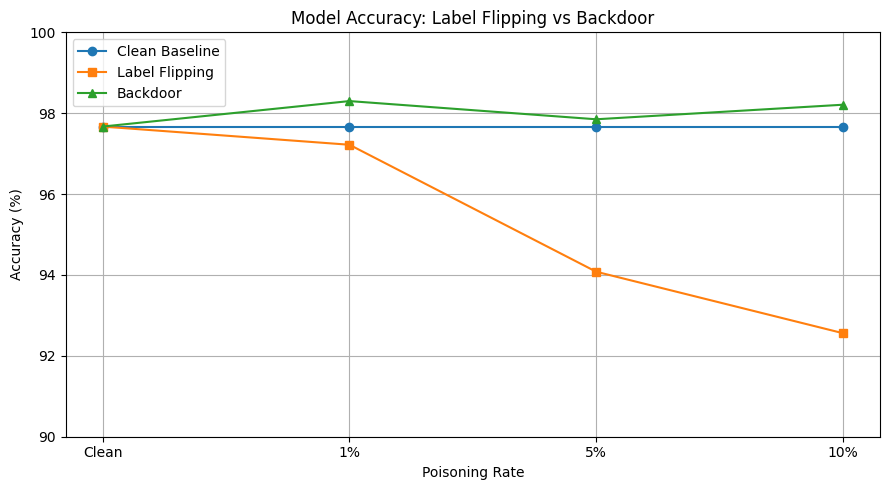

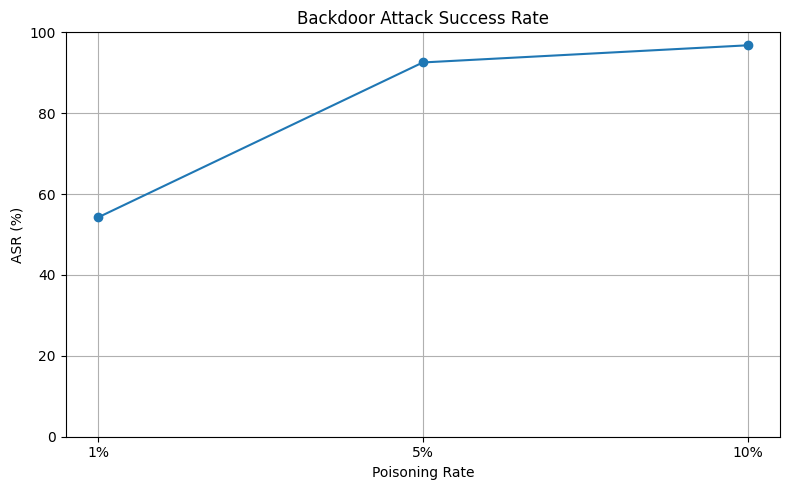

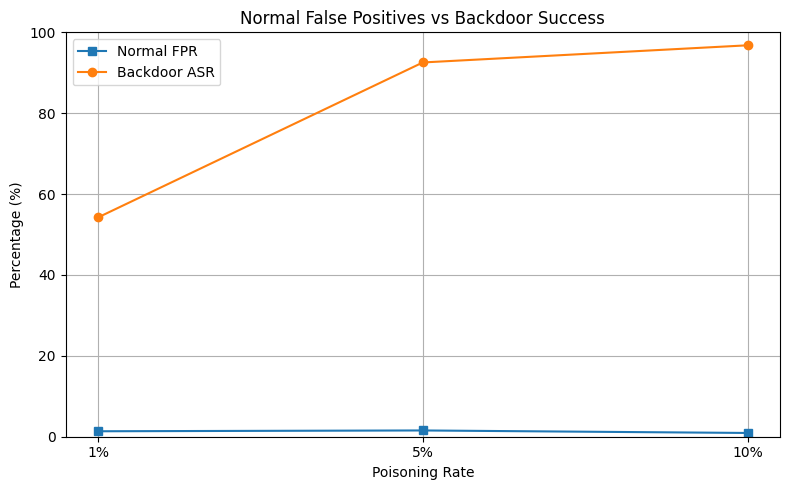

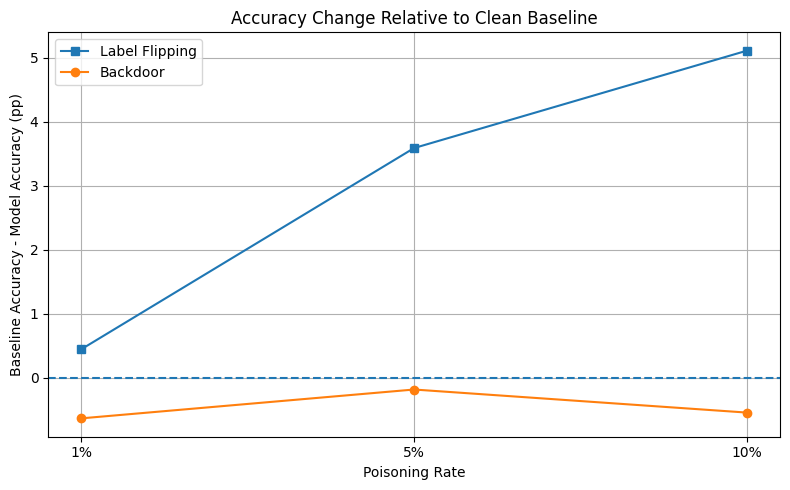

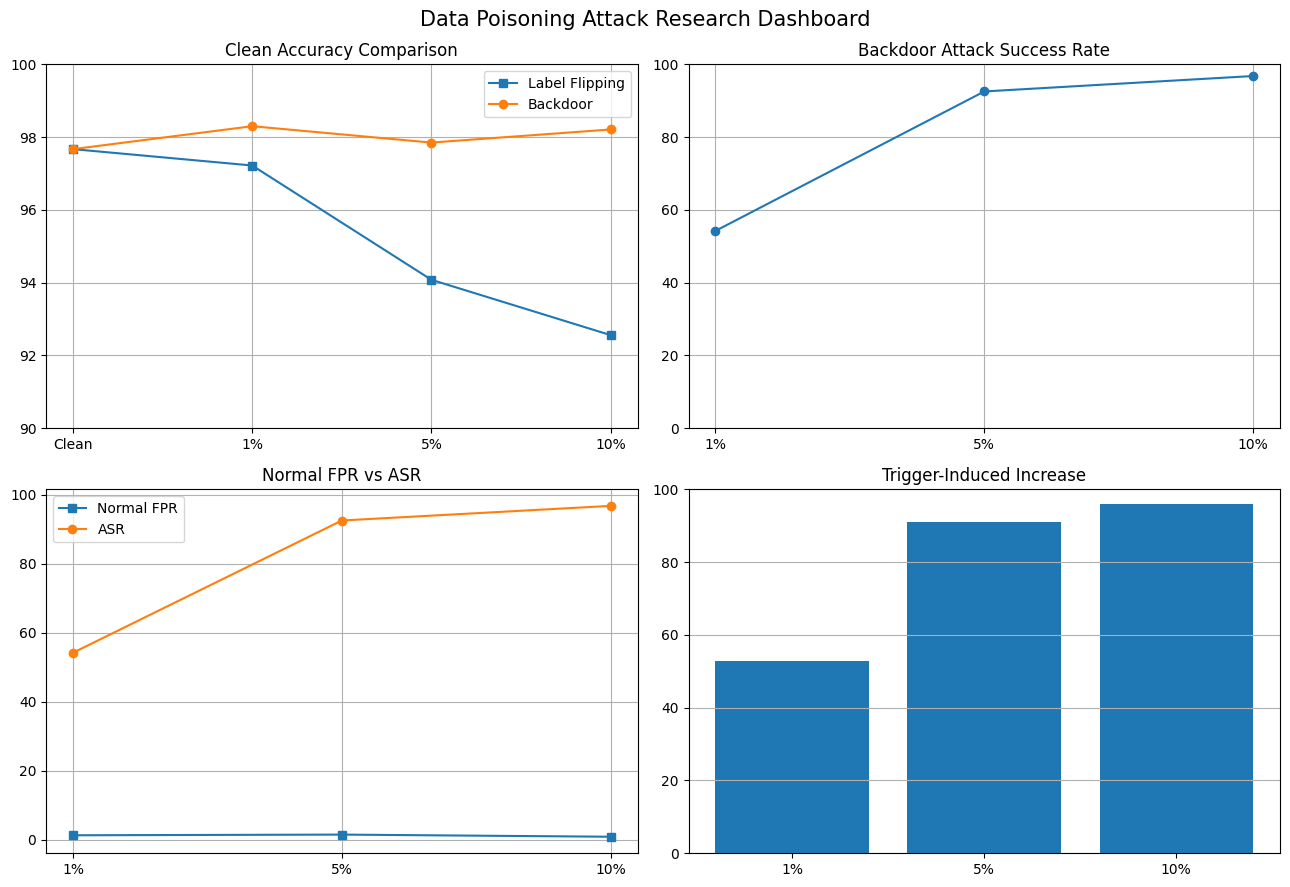


Saved model files: ['backdoor_model_1_percent.pkl', 'backdoor_model_5_percent.pkl', 'backdoor_model_10_percent.pkl', 'backdoor_vectorizer.pkl']

All research artifacts packaged successfully!
Saved models: 4 of 4


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

import os
import shutil
import joblib
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
from google.colab import files

# ==========================================
# 1. CREATE OUTPUT FOLDER
# ==========================================

folder = "Backdoor_Research_Results"
os.makedirs(folder, exist_ok=True)
os.makedirs(f"{folder}/models", exist_ok=True)
os.makedirs(f"{folder}/graphs", exist_ok=True)

# ==========================================
# 2. BACKDOOR EXPERIMENTAL RESULTS
# ==========================================

backdoor_results = pd.DataFrame({
    "Poisoning Rate": ["1%", "5%", "10%"],
    "Poisoned Samples": [44, 222, 445],
    "Clean Accuracy (%)": [98.30, 97.85, 98.21],
    "Normal FPR (%)": [1.35, 1.55, 0.93],
    "ASR (%)": [54.24, 92.55, 96.79],
    "Trigger Increase (pp)": [52.90, 90.99, 95.86]
})

backdoor_results.to_csv(
    f"{folder}/backdoor_experimental_results.csv",
    index=False
)

# ==========================================
# 3. LABEL FLIPPING VS BACKDOOR COMPARISON
# ==========================================

accuracy_comparison = pd.DataFrame({
    "Poisoning Rate": ["Clean", "1%", "5%", "10%"],
    "Clean Baseline (%)": [97.67, 97.67, 97.67, 97.67],
    "Label Flipping (%)": [97.67, 97.22, 94.08, 92.56],
    "Backdoor (%)": [97.67, 98.30, 97.85, 98.21]
})

accuracy_comparison.to_csv(
    f"{folder}/attack_accuracy_comparison.csv",
    index=False
)

with pd.ExcelWriter(
    f"{folder}/complete_experimental_results.xlsx"
) as writer:
    backdoor_results.to_excel(
        writer, sheet_name="Backdoor Results", index=False
    )
    accuracy_comparison.to_excel(
        writer, sheet_name="Attack Comparison", index=False
    )

# ==========================================
# 4. GRAPH 1: ACCURACY COMPARISON
# ==========================================

rates = ["Clean", "1%", "5%", "10%"]

plt.figure(figsize=(9, 5))
plt.plot(rates, accuracy_comparison["Clean Baseline (%)"],
         marker="o", label="Clean Baseline")
plt.plot(rates, accuracy_comparison["Label Flipping (%)"],
         marker="s", label="Label Flipping")
plt.plot(rates, accuracy_comparison["Backdoor (%)"],
         marker="^", label="Backdoor")

plt.title("Model Accuracy: Label Flipping vs Backdoor")
plt.xlabel("Poisoning Rate")
plt.ylabel("Accuracy (%)")
plt.ylim(90, 100)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig(f"{folder}/graphs/01_accuracy_comparison.png", dpi=300)
plt.savefig(f"{folder}/graphs/01_accuracy_comparison.pdf")
plt.show()

# ==========================================
# 5. GRAPH 2: BACKDOOR ASR
# ==========================================

plt.figure(figsize=(8, 5))
plt.plot(
    backdoor_results["Poisoning Rate"],
    backdoor_results["ASR (%)"],
    marker="o",
    label="Attack Success Rate"
)

plt.title("Backdoor Attack Success Rate")
plt.xlabel("Poisoning Rate")
plt.ylabel("ASR (%)")
plt.ylim(0, 100)
plt.grid(True)
plt.tight_layout()
plt.savefig(f"{folder}/graphs/02_backdoor_asr.png", dpi=300)
plt.savefig(f"{folder}/graphs/02_backdoor_asr.pdf")
plt.show()

# ==========================================
# 6. GRAPH 3: NORMAL FPR VS ASR
# ==========================================

plt.figure(figsize=(8, 5))
plt.plot(
    backdoor_results["Poisoning Rate"],
    backdoor_results["Normal FPR (%)"],
    marker="s",
    label="Normal FPR"
)
plt.plot(
    backdoor_results["Poisoning Rate"],
    backdoor_results["ASR (%)"],
    marker="o",
    label="Backdoor ASR"
)

plt.title("Normal False Positives vs Backdoor Success")
plt.xlabel("Poisoning Rate")
plt.ylabel("Percentage (%)")
plt.ylim(0, 100)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig(f"{folder}/graphs/03_fpr_vs_asr.png", dpi=300)
plt.savefig(f"{folder}/graphs/03_fpr_vs_asr.pdf")
plt.show()

# ==========================================
# 7. GRAPH 4: ACCURACY DEGRADATION
# ==========================================

baseline = 97.67

label_drop = [
    baseline - x
    for x in [97.22, 94.08, 92.56]
]

backdoor_drop = [
    baseline - x
    for x in [98.30, 97.85, 98.21]
]

plt.figure(figsize=(8, 5))
plt.plot(["1%", "5%", "10%"], label_drop,
         marker="s", label="Label Flipping")
plt.plot(["1%", "5%", "10%"], backdoor_drop,
         marker="o", label="Backdoor")

plt.axhline(0, linestyle="--")
plt.title("Accuracy Change Relative to Clean Baseline")
plt.xlabel("Poisoning Rate")
plt.ylabel("Baseline Accuracy - Model Accuracy (pp)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig(f"{folder}/graphs/04_accuracy_degradation.png", dpi=300)
plt.savefig(f"{folder}/graphs/04_accuracy_degradation.pdf")
plt.show()

# ==========================================
# 8. GRAPH 5: COMPLETE DASHBOARD
# ==========================================

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

axes[0, 0].plot(rates, accuracy_comparison["Label Flipping (%)"],
                marker="s", label="Label Flipping")
axes[0, 0].plot(rates, accuracy_comparison["Backdoor (%)"],
                marker="o", label="Backdoor")
axes[0, 0].set_title("Clean Accuracy Comparison")
axes[0, 0].set_ylim(90, 100)
axes[0, 0].legend()
axes[0, 0].grid(True)

axes[0, 1].plot(["1%", "5%", "10%"],
                backdoor_results["ASR (%)"], marker="o")
axes[0, 1].set_title("Backdoor Attack Success Rate")
axes[0, 1].set_ylim(0, 100)
axes[0, 1].grid(True)

axes[1, 0].plot(["1%", "5%", "10%"],
                backdoor_results["Normal FPR (%)"],
                marker="s", label="Normal FPR")
axes[1, 0].plot(["1%", "5%", "10%"],
                backdoor_results["ASR (%)"],
                marker="o", label="ASR")
axes[1, 0].set_title("Normal FPR vs ASR")
axes[1, 0].legend()
axes[1, 0].grid(True)

axes[1, 1].bar(["1%", "5%", "10%"],
               backdoor_results["Trigger Increase (pp)"])
axes[1, 1].set_title("Trigger-Induced Increase")
axes[1, 1].set_ylim(0, 100)
axes[1, 1].grid(axis="y")

fig.suptitle("Data Poisoning Attack Research Dashboard", fontsize=15)
plt.tight_layout()
plt.savefig(f"{folder}/graphs/05_complete_dashboard.png", dpi=300)
plt.savefig(f"{folder}/graphs/05_complete_dashboard.pdf")
plt.show()

# ==========================================
# 9. SAVE TRAINED MODELS AND VECTORIZER
# ==========================================

objects_to_save = {
    "backdoor_model_1_percent.pkl": "backdoor_model_1",
    "backdoor_model_5_percent.pkl": "backdoor_model_5",
    "backdoor_model_10_percent.pkl": "backdoor_model_10",
    "backdoor_vectorizer.pkl": "backdoor_vectorizer"
}

saved_models = []

for filename, variable_name in objects_to_save.items():
    if variable_name in globals():
        joblib.dump(
            globals()[variable_name],
            f"{folder}/models/{filename}"
        )
        saved_models.append(filename)
    else:
        print("Not available in memory:", variable_name)

print("\nSaved model files:", saved_models)

# ==========================================
# 10. SAVE EXPERIMENT SUMMARY
# ==========================================

summary = """
DATA POISONING ATTACK EXPERIMENT

Dataset: SMS Spam Collection
Classifier: Logistic Regression
Feature Extraction: TF-IDF
Maximum Features: 5000
Trigger: zxqvtoken
Source Class: Ham (0)
Target Class: Spam (1)

BACKDOOR RESULTS

1% Poisoning:
Clean Accuracy: 98.30%
Normal FPR: 1.35%
ASR: 54.24%

5% Poisoning:
Clean Accuracy: 97.85%
Normal FPR: 1.55%
ASR: 92.55%

10% Poisoning:
Clean Accuracy: 98.21%
Normal FPR: 0.93%
ASR: 96.79%

Label Flipping Accuracy:
Clean Baseline: 97.67%
1%: 97.22%
5%: 94.08%
10%: 92.56%

Note: Backdoor and label-flipping accuracy results are
reported from their respective experiments.
"""

with open(f"{folder}/experiment_summary.txt", "w") as f:
    f.write(summary)

# ==========================================
# 11. CREATE ZIP AND DOWNLOAD
# ==========================================

zip_path = shutil.make_archive(
    "Complete_Backdoor_Research_Package",
    "zip",
    folder
)

print("\nAll research artifacts packaged successfully!")
print("Saved models:", len(saved_models), "of 4")

files.download(zip_path)
